In [7]:
# ============================================================================
# SCRIPT UNIFICADO: Análise Petrecca Rigorosa (Alta/Baixa Freq Separadas), 
# Filtro de Redshift (0.4 a 0.5) e F_var
# ============================================================================

import os
import glob
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.patheffects as patheffects
from scipy.interpolate import interp1d
from astropy.timeseries import LombScargle
import warnings

warnings.filterwarnings('ignore')

In [8]:


# ---------------------- 1. CONFIGURAÇÕES INICIAIS ----------------------
base_dir = r"ztffp_final_data_2025" 
csv_meta_path = r"wu_shen_selected_columns.csv"
band = 'g'
plots_dir_base = "plots_Petrecca_Avancado"
os.makedirs(plots_dir_base, exist_ok=True)

Lendo metadados e aplicando filtros (Z, Mass, Edd)...


Processando Banda G (z: 0.4-0.5): 100%|██████████| 2261/2261 [00:41<00:00, 54.64it/s]



Total de objetos retidos após filtros: 2200
Generating Light Curve Plot with Separated Interpolations (Petrecca)...


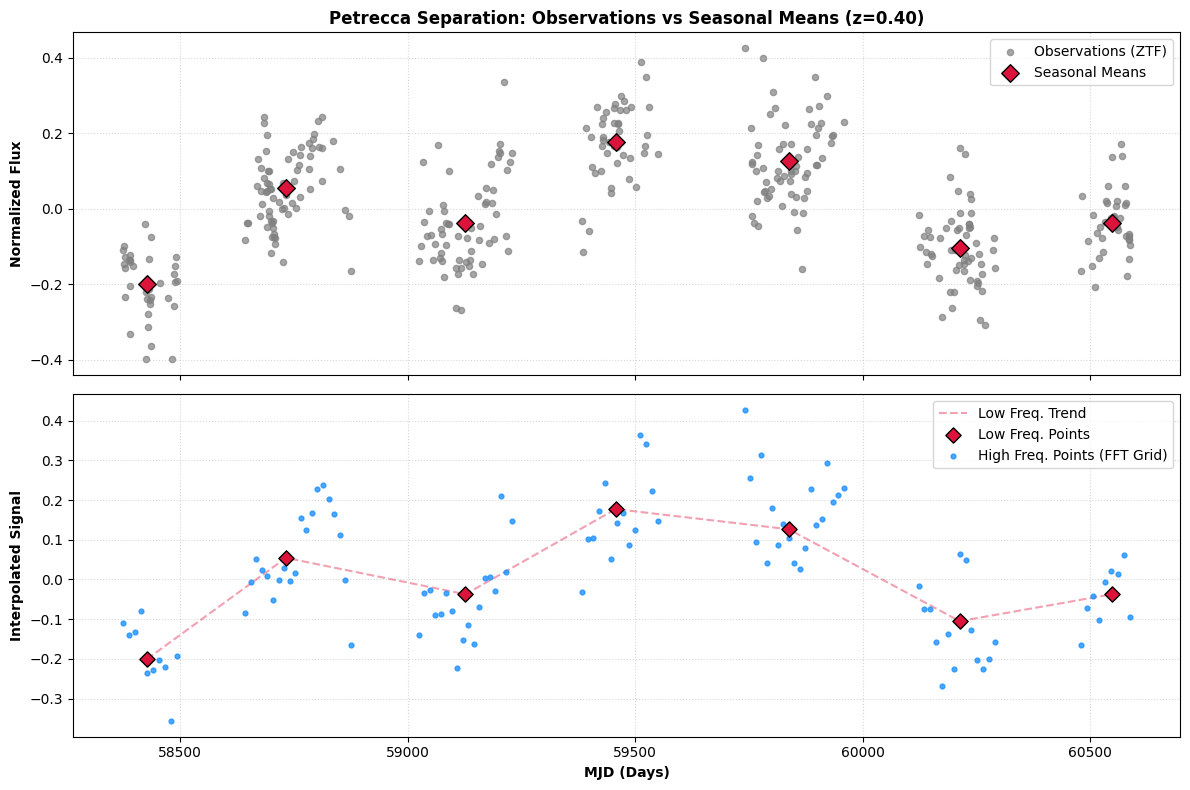

Gerando Matriz Grid de Distribuição...

Concluído! Gráficos salvos em: plots_Petrecca_Avancado


In [10]:
# Parâmetros Petrecca
MIN_CADENCE_DAYS = 12.0    # Petrecca costuma usar bins de 12 dias ou 1 dia
SEASON_GAP_DAYS = 100.0    # Gap que divide as temporadas

# Limites dos Filtros
Z_MIN, Z_MAX = 0.4, 0.5
mass_edges = [7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0]
edd_edges  = [-2.5, -2.0, -1.5, -1.0, -0.5, 0.0, 0.5] 

# ---------------------- 2. LEITURA E PROCESSAMENTO ----------------------
print("Lendo metadados e aplicando filtros (Z, Mass, Edd)...")
try:
    meta = pd.read_csv(csv_meta_path.replace("\\", "/"))
    ra_cat, dec_cat = meta['RA'].values, meta['DEC'].values
    logmbh_cat, logedd_cat = meta['LOGMBH'].values, meta['LOGLEDD_RATIO'].values
    
    # Tenta achar a coluna de Z. Pode ser 'Z' ou 'Z_DR16Q'
    z_col = 'Z_DR16Q' if 'Z_DR16Q' in meta.columns else 'Z'
    z_cat = meta[z_col].values
except FileNotFoundError:
    print(f"AVISO: Arquivo de metadados não encontrado.")
    raise

folders = [f for f in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, f)) and "plots" not in f]
valid_data = []

for folder in tqdm(folders, desc=f"Processando Banda {band.upper()} (z: {Z_MIN}-{Z_MAX})"):
    try: ra_f, dec_f = map(float, folder.split('_'))
    except: continue
    
    dist = np.sqrt((ra_cat - ra_f)**2 + (dec_cat - dec_f)**2)
    idx = np.argmin(dist)
    if dist[idx] > 1e-4: continue
    
    m, e, z = logmbh_cat[idx], logedd_cat[idx], z_cat[idx]
    
    # --- APLICAÇÃO DOS FILTROS FÍSICOS E DE REDSHIFT ---
    if np.isnan(m) or np.isnan(e) or np.isnan(z): continue
    if z < Z_MIN or z > Z_MAX: continue  # <-- FILTRO DE REDSHIFT AQUI
    if m < mass_edges[0] or m >= mass_edges[-1]: continue
    if e < edd_edges[0] or e >= edd_edges[-1]: continue

    txt_files = glob.glob(os.path.join(base_dir, folder, f"*_ztf_{band}_filtered.txt"))
    if not txt_files: continue
    
    try:
        df = pd.read_csv(txt_files[0])
        col_t, col_f = 'mjd', 'flux'
        if len(df) < 10 or col_t not in df.columns or col_f not in df.columns: continue
            
        df = df.sort_values(col_t)
        t_all = df[col_t].values
        f_all = df[col_f].values
        
        # --- Lógica Petrecca: Separar Temporadas Rigorosamente ---
        gaps = np.diff(t_all)
        season_breaks = np.where(gaps > SEASON_GAP_DAYS)[0] + 1
        season_indices = np.split(np.arange(len(t_all)), season_breaks)
        
        seasons_t = []
        seasons_f = []
        t_season_means = []
        f_season_means = []
        
        for s_idx in season_indices:
            if len(s_idx) > 3: # Exige um mínimo de pontos por temporada
                t_s, f_s = t_all[s_idx], f_all[s_idx]
                seasons_t.append(t_s)
                seasons_f.append(f_s)
                t_season_means.append(np.mean(t_s))
                f_season_means.append(np.mean(f_s))
                
        y_norm_all = (f_all - np.median(f_all)) / np.median(f_all)
        
        # Normalização das médias sazonais (Baixas Frequências)
        y_season_norm = (np.array(f_season_means) - np.median(f_all)) / np.median(f_all)
        
        # Normalização intra-temporadas (Altas Frequências)
        seasons_f_norm = [(f_s - np.median(f_all)) / np.median(f_all) for f_s in seasons_f]
        
        valid_data.append({
            't_raw': t_all, 'flux_norm': y_norm_all, 
            'seasons_t': seasons_t, 'seasons_f_norm': seasons_f_norm,
            't_season_means': np.array(t_season_means), 'flux_season_means': y_season_norm,
            'T_total': t_all.max() - t_all.min(), 
            'LOGMBH': m, 'LOGLEDD_RATIO': e, 'Z': z
        })
            
    except Exception as error: 
        continue

if not valid_data:
    raise ValueError(f"Nenhum dado válido após aplicar os filtros (z entre {Z_MIN} e {Z_MAX}).")

print(f"\nTotal de objetos retidos após filtros: {len(valid_data)}")

# ---------------------- # ---------------------- 3. PLOT A: PETRECCA INTERPOLATION (NO GAP CROSSING) ----------------------
print("Generating Light Curve Plot with Separated Interpolations (Petrecca)...")
ex_data = valid_data[0] # Take the first object as an example
t_raw, f_norm = ex_data['t_raw'], ex_data['flux_norm']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Panel 1: Raw Data + Seasonal Means
ax1.scatter(t_raw, f_norm, color='gray', s=20, alpha=0.7, label='Observations (ZTF)')
ax1.scatter(ex_data['t_season_means'], ex_data['flux_season_means'], color='crimson', s=80, marker='D', edgecolor='black', zorder=5, label='Seasonal Means')
ax1.set_ylabel('Normalized Flux', fontweight='bold')
ax1.set_title(f'Petrecca Separation: Observations vs Seasonal Means (z={ex_data["Z"]:.2f})', fontweight='bold')
ax1.legend()
ax1.grid(ls=':', alpha=0.5)

# Panel 2: Interpolations (High vs Low freq)

# 1. Low Frequencies (Crosses everything, as it represents the long-term trend)
if len(ex_data['t_season_means']) > 1:
    t_grid_low = np.linspace(ex_data['t_season_means'].min(), ex_data['t_season_means'].max(), 200)
    intp_low = interp1d(ex_data['t_season_means'], ex_data['flux_season_means'], kind='linear', bounds_error=False, fill_value='extrapolate')(t_grid_low)
    
    # Faded line following the long-term trend
    ax2.plot(t_grid_low, intp_low, color='crimson', lw=1.5, ls='--', alpha=0.4, label='Low Freq. Trend')
    # Low frequency points (Seasonal Means)
    ax2.scatter(ex_data['t_season_means'], ex_data['flux_season_means'], color='crimson', s=60, marker='D', edgecolor='black', zorder=5, label='Low Freq. Points')

# 2. High Frequencies (ONLY interpolates within the season, respecting observational gaps)
for s_idx, (t_s, f_s) in enumerate(zip(ex_data['seasons_t'], ex_data['seasons_f_norm'])):
    # Using MIN_CADENCE_DAYS to define the FFT point grid
    t_grid_high = np.linspace(t_s.min(), t_s.max(), int((t_s.max()-t_s.min())/MIN_CADENCE_DAYS) + 1)
    if len(t_grid_high) > 1:
        intp_high = interp1d(t_s, f_s, kind='linear')(t_grid_high)
        lbl = 'High Freq. Points (FFT Grid)' if s_idx == 0 else ""
        
        # Plotting as scatter instead of a continuous line
        ax2.scatter(t_grid_high, intp_high, color='dodgerblue', s=12, alpha=0.8, zorder=3, label=lbl)

ax2.set_xlabel('MJD (Days)', fontweight='bold')
ax2.set_ylabel('Interpolated Signal', fontweight='bold')
ax2.legend()
ax2.grid(ls=':', alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(plots_dir_base, f"LC_Interpolation_Petrecca_{band}.png"), dpi=200)
plt.show()

# ---------------------- 4. PLOT B: GRID DE MASSA VS EDDINGTON (Amostra Filtrada) ----------------------
print("Gerando Matriz Grid de Distribuição...")
m_arr = np.array([d['LOGMBH'] for d in valid_data])
e_arr = np.array([d['LOGLEDD_RATIO'] for d in valid_data])

fig, ax = plt.subplots(figsize=(8, 6))
H, xe, ye = np.histogram2d(m_arr, e_arr, bins=(mass_edges, edd_edges))
H = H.T

X, Y = np.meshgrid(xe, ye)
mesh = ax.pcolormesh(X, Y, H, cmap='Blues', edgecolor='black', linewidth=0.5)
plt.colorbar(mesh, ax=ax, label='Contagem de Objetos')

for i in range(len(ye)-1):
    for j in range(len(xe)-1):
        if H[i,j] > 0:
            txt = ax.text(xe[j]+0.25, ye[i]+0.25, str(int(H[i,j])), ha='center', va='center', fontweight='bold', color='black')
            txt.set_path_effects([patheffects.withStroke(linewidth=2, foreground='white')])

ax.set_xticks(mass_edges)
ax.set_yticks(edd_edges)
ax.set_xlabel(r'$\log M_{\rm{BH}} \ [M_{\odot}]$', fontweight='bold')
ax.set_ylabel(r'$\log (L_{\rm{bol}}/L_{\rm{Edd}})$', fontweight='bold')
ax.set_title(f'Distribuição da Amostra (z: {Z_MIN}-{Z_MAX})', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(plots_dir_base, f"Mass_Edd_Grid_Distribution_{band}.png"), dpi=200)
plt.close()

print(f"\nConcluído! Gráficos salvos em: {plots_dir_base}")